# 05 · BERT sentiment: does the text of reviews follow ratings, popularity and sales?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings**

- A ready-trained **BERT** model read **20,000 reviews** and was within one star of the reader for **95.2%** of them (baseline 89.1%). It is a bit more careful than readers: it
  often reads 5 stars as 4.
- The tone **does not separate popular books** (mean BERT stars **4.24** against 4.20) or verified buyers (4.24 against 4.22).
- The tone is **not related to sales** (correlation **−0.03**). Only the best-selling books have more negative texts (**13.8%** against 6–8%), because they reach more readers.

**In short:** reviews describe how satisfied readers are, not how many readers a book has.

## 2. Recap

The models in `02.x` predict popularity from a book draft. Reviews are written **after** publication, so they cannot be used there. This notebook is a
**separate analysis** of what the text adds:

1. Does **BERT** read the same opinion from the text as the reader's **stars**?
2. Is the text of **popular** books more positive?
3. Do **verified buyers** write differently?
4. Does the tone follow the **copies sold** of the book (`04_eda_with_synthetic_sales.ipynb`)?

## 3. Setup

**BERT** is a language model trained on a very large amount of text. I use a version that was already trained to read the opinion of product reviews
and to give **1 to 5 stars**: `nlptown/bert-base-multilingual-uncased-sentiment`. I do not train it. BERT is beyond the course methods, and the instructor
suggested trying it.

BERT needs a lot of computing. With the graphics card of this computer it reads about 90 reviews per second, so all 1.9 million reviews of my books
would take about 6 hours. I therefore use a **random sample of 20,000 reviews**.

In [1]:
import logging
import os
from pathlib import Path

os.environ["TORCH_CPP_LOG_LEVEL"] = "ERROR"          # hide technical messages of torch on Windows
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error
from transformers import logging as transformers_logging, pipeline

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
REVIEWS_FILE = PROJECT / "data" / "raw" / "Kindle_Store_reviews.jsonl"
PROCESSED = PROJECT / "data" / "processed"
MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
SAMPLE_SIZE = 20_000
SEED = 42
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
DEVICE = 0 if torch.cuda.is_available() else -1
print("Graphics card:", torch.cuda.get_device_name(0) if DEVICE == 0 else "none, BERT runs on the processor (slower)")

Graphics card: NVIDIA GeForce RTX 5060 Laptop GPU


## 4. Feature preparation

I take the reviews of the **135,839 books** from the popularity table (`01_eda.ipynb`), published from 2019 to 2021: the text, the reader's stars,
`verified_purchase` and the date. Then I draw the random sample. Empty texts are removed.

In [2]:
popularity = pd.read_parquet(PROCESSED / "kindle_books_popularity.parquet", columns=["parent_asin", "niche", "self_published", "popular_first_year"])
reviews = (pl.scan_ndjson(REVIEWS_FILE)
           .select("parent_asin", "rating", "title", "text", "verified_purchase")
           .filter(pl.col("parent_asin").is_in(popularity["parent_asin"].to_list()))
           .collect(engine="streaming"))
print(f"Reviews of my books: {len(reviews):,}")
reviews = reviews.filter(pl.col("text").str.strip_chars().str.len_chars() > 0)
sample = reviews.sample(n=SAMPLE_SIZE, seed=SEED).to_pandas().merge(popularity, on="parent_asin")
del reviews
sample["text_words"] = sample["text"].str.split().str.len()
print(f"Sample: {len(sample):,} reviews of {sample['parent_asin'].nunique():,} books")
print(f"Median words per review: {sample['text_words'].median():.0f}")
display(sample["rating"].value_counts(normalize=True).sort_index().mul(100).round(1).to_frame("stars %"))
sample[["rating", "title", "text", "verified_purchase"]].head(3)

Reviews of my books: 1,928,793


Sample: 20,000 reviews of 13,035 books
Median words per review: 45


,stars %
rating,
1.0,2.4
2.0,2.7
3.0,5.8
4.0,18.3
5.0,70.9


,rating,title,text,verified_purchase
0,5.0,Very enjoyable reading,"I found the characters likeable, quirky, and the story intriguing.",True
1,5.0,Great YA story,Sometimes I just want to go back to the kind of books I read as a YA when life was sim...,False
2,4.0,Good Book,OK BUT the ending left me wanting for more.<br />Their relationship needs to be more f...,True


- My books have **1,928,793** reviews with text in the file. The sample has **20,000** reviews of **13,035** books.
- A median review has **45 words**.
- **70.9%** of the reviews give 5 stars and only **5.1%** give 1 or 2. Readers who write reviews are mostly satisfied.

## 5. Train/test split

No split is needed: BERT is used **as it is**, without training on my data. All 20,000 reviews are test data, and the reader's own stars are the
correct answers.

## 6. Baseline

The baseline always predicts the most common number of stars. BERT must do better.

In [3]:
most_common = sample["rating"].mode()[0]
baseline = pd.Series({"accuracy (exact stars)": accuracy_score(sample["rating"], np.full(len(sample), most_common)),
                      "within 1 star": (np.abs(sample["rating"] - most_common) <= 1).mean(),
                      "mean absolute error (stars)": mean_absolute_error(sample["rating"], np.full(len(sample), most_common))})
print("Baseline always predicts:", int(most_common), "stars")
baseline.round(3).to_frame("baseline")

Baseline always predicts: 5 stars


,baseline
accuracy (exact stars),0.708
within 1 star,0.891
mean absolute error (stars),0.474


- The baseline always predicts **5 stars**. Because most reviews have 5 stars, it is right for **70.8%** of them, within one star for **89.1%**, with a mean error of **0.474** stars.
- This is a hard baseline for exact stars, so the most useful measures here are **within 1 star** and the **mean error**.

## 7. Candidate model

BERT reads at most 512 word pieces; I cut each review at **256**, which is enough for most reviews (the median review has 45 words). The result is a label from "1 star" to
"5 stars" and a confidence score. I keep the number of stars as `bert_stars`.

In [4]:
classifier = pipeline("sentiment-analysis", model=MODEL_NAME, device=DEVICE, truncation=True, max_length=256)
texts = (sample["title"].fillna("") + ". " + sample["text"]).tolist()
predictions = classifier(texts, batch_size=64)
sample["bert_stars"] = [int(p["label"][0]) for p in predictions]
sample["bert_confidence"] = [p["score"] for p in predictions]
sample[["rating", "bert_stars", "bert_confidence", "text"]].head(5).round(2)

,rating,bert_stars,bert_confidence,text
0,5.0,4,0.74,"I found the characters likeable, quirky, and the story intriguing."
1,5.0,4,0.54,Sometimes I just want to go back to the kind of books I read as a YA when life was sim...
2,4.0,3,0.70,OK BUT the ending left me wanting for more.<br />Their relationship needs to be more f...
3,5.0,4,0.73,Death is mysterious and a part of him is sheltered. He‘s not use to emotions since he ...
4,5.0,4,0.64,“A Rose to the Torch” up-ends the typical urban dark fantasy tropes. The protagonist-w...


- BERT gives each review a number of stars and a confidence. For the first reviews it gives **4** stars where the reader gave 5, with a confidence of about 0.5–0.7.

## 8. Evaluation

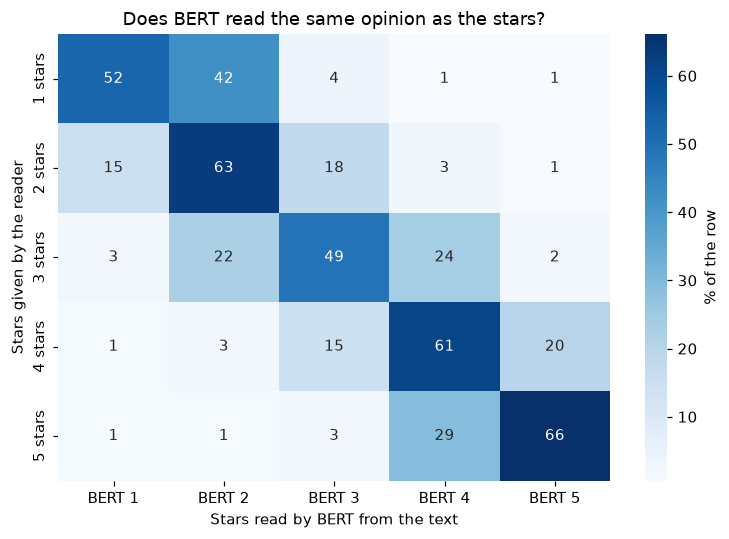

Spearman correlation between stars and BERT: 0.58


,baseline,BERT
accuracy (exact stars),0.708,0.638
within 1 star,0.891,0.952
mean absolute error (stars),0.474,0.438


In [5]:
scores = pd.DataFrame({
    "baseline": baseline,
    "BERT": pd.Series({"accuracy (exact stars)": accuracy_score(sample["rating"], sample["bert_stars"]),
                       "within 1 star": (np.abs(sample["rating"] - sample["bert_stars"]) <= 1).mean(),
                       "mean absolute error (stars)": mean_absolute_error(sample["rating"], sample["bert_stars"])}),
})
matrix = pd.DataFrame(confusion_matrix(sample["rating"], sample["bert_stars"], labels=[1, 2, 3, 4, 5]),
                      index=[f"{i} stars" for i in range(1, 6)], columns=[f"BERT {i}" for i in range(1, 6)])
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(matrix.div(matrix.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of the row"}, ax=ax)
ax.set_xlabel("Stars read by BERT from the text")
ax.set_ylabel("Stars given by the reader")
ax.set_title("Does BERT read the same opinion as the stars?")
plt.tight_layout()
plt.show()
print(f"Spearman correlation between stars and BERT: {sample['rating'].corr(sample['bert_stars'], method='spearman'):.2f}")
scores.round(3)

- BERT is **within one star** of the reader in **95.2%** of the reviews (baseline 89.1%), and its mean error is lower (**0.438** against 0.474 stars).
- Its exact accuracy is **63.8%**, lower than the baseline (70.8%), because it often reads a 5-star review as 4 stars. BERT is more careful than readers.
- The Spearman correlation with the stars is **0.58**: the text and the stars agree in direction, but not exactly.
- So BERT reads the opinion of the text well, but it would not replace the stars.

## 9. Error analysis

Where do text and stars disagree most? I show reviews with 5 stars that BERT reads as 1 star, and the opposite.

In [6]:
sample["difference"] = sample["bert_stars"] - sample["rating"]
show = ["rating", "bert_stars", "bert_confidence", "verified_purchase", "text"]
high_stars_negative_text = sample[(sample["rating"] == 5) & (sample["bert_stars"] == 1)].nlargest(4, "bert_confidence")[show]
low_stars_positive_text = sample[(sample["rating"] == 1) & (sample["bert_stars"] == 5)].nlargest(4, "bert_confidence")[show]
print(f"5 stars but BERT reads 1: {len(sample[(sample['rating'] == 5) & (sample['bert_stars'] == 1)]):,} | "
      f"1 star but BERT reads 5: {len(sample[(sample['rating'] == 1) & (sample['bert_stars'] == 5)]):,}")
display(high_stars_negative_text.assign(text=lambda d: d["text"].str[:160]).round(2))
display(low_stars_positive_text.assign(text=lambda d: d["text"].str[:160]).round(2))
sample.groupby(pd.cut(sample["text_words"], [0, 10, 30, 100, np.inf], labels=["1-10 words", "11-30", "31-100", "100+"]), observed=True).apply(
    lambda d: pd.Series({"reviews": len(d), "exact %": (d["rating"] == d["bert_stars"]).mean() * 100,
                         "within 1 star %": (d["difference"].abs() <= 1).mean() * 100})).round(1)

5 stars but BERT reads 1: 174 | 1 star but BERT reads 5: 4


,rating,bert_stars,bert_confidence,verified_purchase,text
17158,5.0,1,0.94,False,"Ohmygosh. There are just so many feels. First and foremost, I love that our FMC - Mari..."
11478,5.0,1,0.92,True,Junk Mail made me laugh so hard I had tears streaming down my cheeks. I couldn't put i...
8154,5.0,1,0.90,False,I'm stunned. Please say this isn't the end! There is still so much to know!!! I can on...
18696,5.0,1,0.83,True,"This book is horrible. And beautiful. Gut wrenching, sob inducing. Keep your tissues c..."


,rating,bert_stars,bert_confidence,verified_purchase,text
12333,1.0,5,0.82,False,Loved this book- looking forward to reading others by her!
19022,1.0,5,0.55,False,Another masterpiece orchestrated by Marci Turk. Not only did Howard steal the name fro...
3712,1.0,5,0.45,True,"One if not the worse book I 'have read in a long time. To descriptive, really wh..."
19156,1.0,5,0.33,True,I definitely would not read this any child I know! The little boy starts off taking a ...


,reviews,exact %,within 1 star %
text_words,,,
1-10 words,741.0,68.2,95.0
11-30,5857.0,68.3,95.7
31-100,9024.0,65.2,95.3
100+,4378.0,54.2,94.5


- Big disagreements are rare: **174** reviews have 5 stars but BERT reads 1, and only **4** have 1 star but BERT reads 5.
- Most 5-star reviews read as negative are **strong emotions** in positive reviews ("This book is horrible. And beautiful. Gut wrenching..."). BERT reads the strong words, not
  the meaning.
- Some 1-star reviews read as positive look like **mistakes by the reader** ("Loved this book- looking forward to reading others by her!" with 1 star).
- BERT is less exact for long reviews: **54.2%** exact for 100+ words against about 68% for short ones, but it stays within one star for about **95%** of all lengths.

## 10. Interpretation

Now the questions of this notebook: is the tone different for **popular** books, for **verified buyers**, and does it follow **sales**? I compare the
mean of the reader's stars and of BERT's stars, and the share of negative texts (BERT 1–2 stars).

,reviews,mean stars,mean BERT stars,negative text %
popular_first_year,,,,
not popular,3603.0,4.53,4.20,7.38
popular,16397.0,4.52,4.24,8.36


,reviews,mean stars,mean BERT stars,negative text %
verified_purchase,,,,
not verified,8885.0,4.50,4.22,7.62
verified buyer,11115.0,4.55,4.24,8.64


Reviews of books with synthetic sales: 5,984 | Spearman correlation between BERT stars and copies a year: -0.03


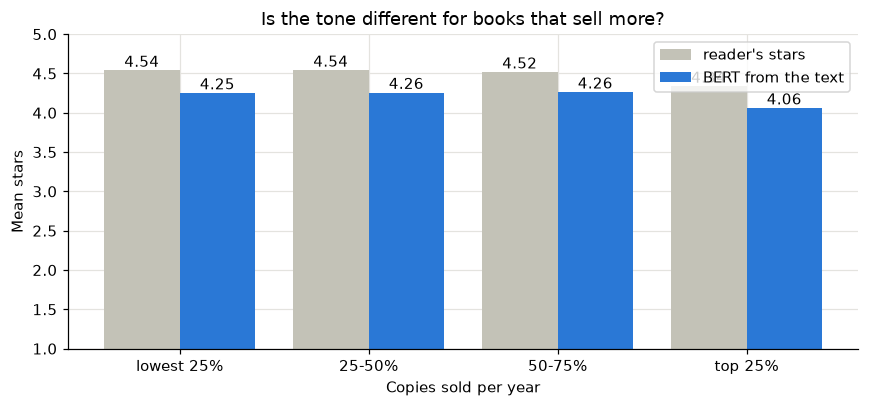

,reviews,mean stars,mean BERT stars,negative text %
sales_group,,,,
lowest 25%,1497.0,4.54,4.25,6.08
25-50%,1495.0,4.54,4.26,6.82
50-75%,1496.0,4.52,4.26,7.69
top 25%,1496.0,4.34,4.06,13.77


In [7]:
def tone(data):
    return pd.Series({"reviews": len(data), "mean stars": data["rating"].mean(), "mean BERT stars": data["bert_stars"].mean(),
                      "negative text %": (data["bert_stars"] <= 2).mean() * 100})


display(sample.groupby("popular_first_year").apply(tone).rename(index={0: "not popular", 1: "popular"}).round(2))
display(sample.groupby("verified_purchase").apply(tone).rename(index={False: "not verified", True: "verified buyer"}).round(2))

income = pd.read_parquet(PROCESSED / "kindle_books_sales_income.parquet", columns=["parent_asin", "copies_per_year"])
with_sales = sample.merge(income, on="parent_asin")
with_sales["sales_group"] = pd.qcut(with_sales["copies_per_year"], 4, labels=["lowest 25%", "25-50%", "50-75%", "top 25%"])
print(f"Reviews of books with synthetic sales: {len(with_sales):,} "
      f"| Spearman correlation between BERT stars and copies a year: "
      f"{with_sales['bert_stars'].corr(with_sales['copies_per_year'], method='spearman'):.2f}")
by_sales = with_sales.groupby("sales_group", observed=True).apply(tone)

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(by_sales))
ax.bar(x - 0.2, by_sales["mean stars"], width=0.4, color=GREY, label="reader's stars")
ax.bar(x + 0.2, by_sales["mean BERT stars"], width=0.4, color=BLUE, label="BERT from the text")
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.bar_label(ax.containers[1], fmt="%.2f")
ax.set_xticks(x, by_sales.index)
ax.set_ylim(1, 5)
ax.set_xlabel("Copies sold per year")
ax.set_ylabel("Mean stars")
ax.set_title("Is the tone different for books that sell more?")
ax.legend()
plt.tight_layout()
plt.show()
by_sales.round(2)

- **Popular books:** the tone is almost the same (mean BERT stars **4.24** against **4.20**, readers' stars 4.52 against 4.53). Popular books do not get kinder reviews, they
  get **more** reviews.
- **Verified buyers** write almost the same as other reviewers (**4.24** against 4.22).
- **Sales:** the correlation between BERT stars and copies sold a year is **−0.03**, so practically none. Only the top 25% of books by sales have more negative texts
  (**13.8%** against 6–8%) and lower stars (4.34 against 4.52–4.54). A book that sells a lot also reaches readers who like it less.
- This agrees with the EDA: stars and tone describe satisfaction, while popularity and sales depend on **how many** readers a book reaches.

## 11. Limitations & ethics

- **A sample of 20,000 reviews**, not all 1.9 million. The sample is random, so it represents the reviews well, but not every book has reviews in it.
- **BERT is not perfect:** it does not understand irony well, and it was trained on product reviews in several languages, not on book reviews.
- **The stars are the reader's own opinion**, so they are the best available check, but a reader may give 5 stars and still write about problems.
- **Copies sold are synthetic example data**, so the link with sales is an example.
- Reviews are written after publication: this analysis **describes** books, it does not predict popularity from a draft.
- Review texts are personal opinions. I show only short parts of a few texts, without user names.

## 12. Conclusion

**What BERT adds.** It reads the opinion of a review almost like the reader's stars (within one star for 95.2%), and it finds reviews where the text and the stars
disagree. This is useful for describing what readers say.

**What it does not add.** The tone of reviews does not separate popular books and is not related to sales. It also cannot be used to predict from a draft, because reviews come
after publication.

**For a future author.** Most reviews are positive whatever the book's success. To sell more, a book needs to reach more readers; good reviews alone do not show that.

In [8]:
sample[["parent_asin", "rating", "bert_stars", "bert_confidence", "verified_purchase", "popular_first_year"]].to_parquet(
    PROCESSED / "bert_sentiment_sample.parquet", index=False)
print("Saved:", len(sample), "reviews")

Saved: 20000 reviews
